04 · Galeri kesalahan dan Grad-CAM (T4-A) — pemegang: Anggota 4
Memenuhi Kisi-Kisi 3.4: (1) galeri minimal 8 contoh terburuk dikelompokkan ke kategori kesalahan beserta frekuensinya, (2) peta Grad-CAM untuk 4 kasus benar dan 4 kasus salah beserta tafsirannya.

Prasyarat: bobot final ada di checkpoints/ (unet_final_seed42.pt, deeplabv3plus_final_seed42.pt) dan code/analysis.py sudah diunggah. Runtime: T4 GPU disarankan (CPU tetap bisa, lebih lambat). Buka lewat File → Save a copy in Drive.

Penting tentang kategori kesalahan: kategorinya dihitung dari ATURAN (jenis kesalahan piksel terbanyak), bukan label manusia. Setelah melihat galerinya, cek visual dan sesuaikan nama atau tafsirannya di laporan. Frekuensi di tabel adalah angka dari aturan itu.


[ ]


In [23]:
# ===== SEL 1: setup (jalankan tiap sesi Colab baru) =====
from google.colab import drive; drive.mount('/content/drive')
import os, sys, glob
DRIVE = "/content/drive/MyDrive/PROYEK UAS DEEP LEARNING"
!apt-get install -y unrar > /dev/null 2>&1
!pip -q install albumentations segmentation-models-pytorch
if not os.path.exists("/content/raabin_gt/bmp/Train_bmp"):
    !mkdir -p /content/raabin_gt/bmp
    !cp "{DRIVE}/GroundTruths_bmpformat.rar" /content/gt.rar
    !unrar x -o+ -inul /content/gt.rar /content/raabin_gt/bmp/
sys.path.append(f"{DRIVE}/code")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from PIL import Image
from data import load_split
from metrics import per_image_metrics
from analysis import (load_model, get_sample, predict, categorize, seg_gradcam,
                      cam_energy_shares, CAT_NAMES)
os.makedirs(f"{DRIVE}/results", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ARCH, SEED, SIZE = "unet", 42, 256        # ganti ARCH ke "deeplabv3plus" untuk model kedua
print("device:", device)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cpu


In [25]:
ARCH, SEED, SIZE = "deeplabv3plus", 42, 256     # untuk model kedua, ubah "unet" menjadi "deeplabv3plus" (nama ARCH jangan diubah)
print("ARCH =", ARCH)

ARCH = deeplabv3plus


In [26]:
# ===== SEL 2: muat model final, prediksi seluruh set uji, hitung metrik dan kategori =====
CKPT_DIR = {
    "unet": f"{DRIVE}/checkpoints",
    "deeplabv3plus": f"{DRIVE}/checkpoints (1)",
}
ckpt = f"{CKPT_DIR[ARCH]}/{ARCH}_final_seed{SEED}.pt"
assert os.path.exists(ckpt), f"Bobot tidak ditemukan: {ckpt}"
model = load_model(ARCH, ckpt, device)
test = load_split("grouped", "test")

rows, preds = [], {}
for n, c in zip(test["name"], test["cls"]):
    img, gt, x = get_sample(n, SIZE)
    pred = predict(model, x, gt.shape, device)
    r = per_image_metrics(pred, gt)
    cat, types, extra = categorize(gt, pred)
    r.update(name=n, cls=c, kategori=cat, objek_ekstra=extra, **{f"px_{k}": v for k, v in types.items()})
    rows.append(r); preds[n] = pred
res = pd.DataFrame(rows)
res["dice_rerata"] = (res.dice_cyto + res.dice_nuc) / 2
os.makedirs(f"{DRIVE}/results", exist_ok=True)
res.to_csv(f"{DRIVE}/results/kesalahan_{ARCH}_seed{SEED}.csv", index=False)
print("Citra uji:", len(res), "| rerata Dice sitoplasma/nukleus:",
      round(res.dice_cyto.mean(), 4), "/", round(res.dice_nuc.mean(), 4))

# pemeriksaan: hasil prediksi ulang harus cocok dengan angka di log (selisih kecil karena presisi)
log_files = glob.glob(f"{DRIVE}/**/log_*.csv", recursive=True)
logs = pd.concat([pd.read_csv(f) for f in log_files]).drop_duplicates("run_id")
run = logs[(logs.ablation == "main") & (logs.arch == ARCH) & (logs.seed == SEED)].run_id.iloc[0]
ref = pd.read_csv(glob.glob(f"{DRIVE}/**/{run}_test_per_image.csv", recursive=True)[0]).set_index("name")
diff = (res.set_index("name").dice_cyto - ref.dice_cyto).abs()
print("Selisih Dice sitoplasma vs berkas log: median", round(diff.median(), 5), "| maks", round(diff.max(), 5))

Citra uji: 108 | rerata Dice sitoplasma/nukleus: 0.9095 / 0.97
Selisih Dice sitoplasma vs berkas log: median 3e-05 | maks 0.00061


In [27]:
# ===== SEL 3: frekuensi kategori kesalahan pada citra terburuk =====
FRAC = 0.25                                    # 25% citra dengan Dice rerata terendah
cut = res.dice_rerata.quantile(FRAC)
bad = res[res.dice_rerata <= cut]
print(f"Citra 'buruk' (Dice rerata <= {cut:.4f}): {len(bad)} dari {len(res)}\n")

freq = bad.kategori.map(CAT_NAMES).value_counts()
print("Frekuensi kategori utama:"); print(freq.to_string())
print("\nObjek ekstra (komponen prediksi yang tidak menyentuh sel gt):", int(bad.objek_ekstra.sum()), "citra")
print("\nKategori x jenis sel:"); print(pd.crosstab(bad.kategori, bad.cls).to_string())
print("\nProporsi citra buruk per jenis sel:")
print(res.assign(buruk=res.dice_rerata <= cut).groupby("cls").buruk.agg(["mean", "sum", "count"]).round(3).to_string())


Citra 'buruk' (Dice rerata <= 0.9324): 27 dari 108

Frekuensi kategori utama:
kategori
Sitoplasma kurang (sitoplasma dilabeli latar)      10
Sitoplasma berlebih (latar dilabeli sitoplasma)     9
Inti dan sitoplasma tertukar                        8

Objek ekstra (komponen prediksi yang tidak menyentuh sel gt): 0 citra

Kategori x jenis sel:
cls                       Eosinophil  Lymphocyte  Monocyte  Neutrophil
kategori                                                              
inti_sitoplasma_tertukar           2           5         1           0
sitoplasma_berlebih                1           7         1           0
sitoplasma_kurang                  0           7         2           1

Proporsi citra buruk per jenis sel:
             mean  sum  count
cls                          
Eosinophil  0.231    3     13
Lymphocyte  0.613   19     31
Monocyte    0.121    4     33
Neutrophil  0.032    1     31


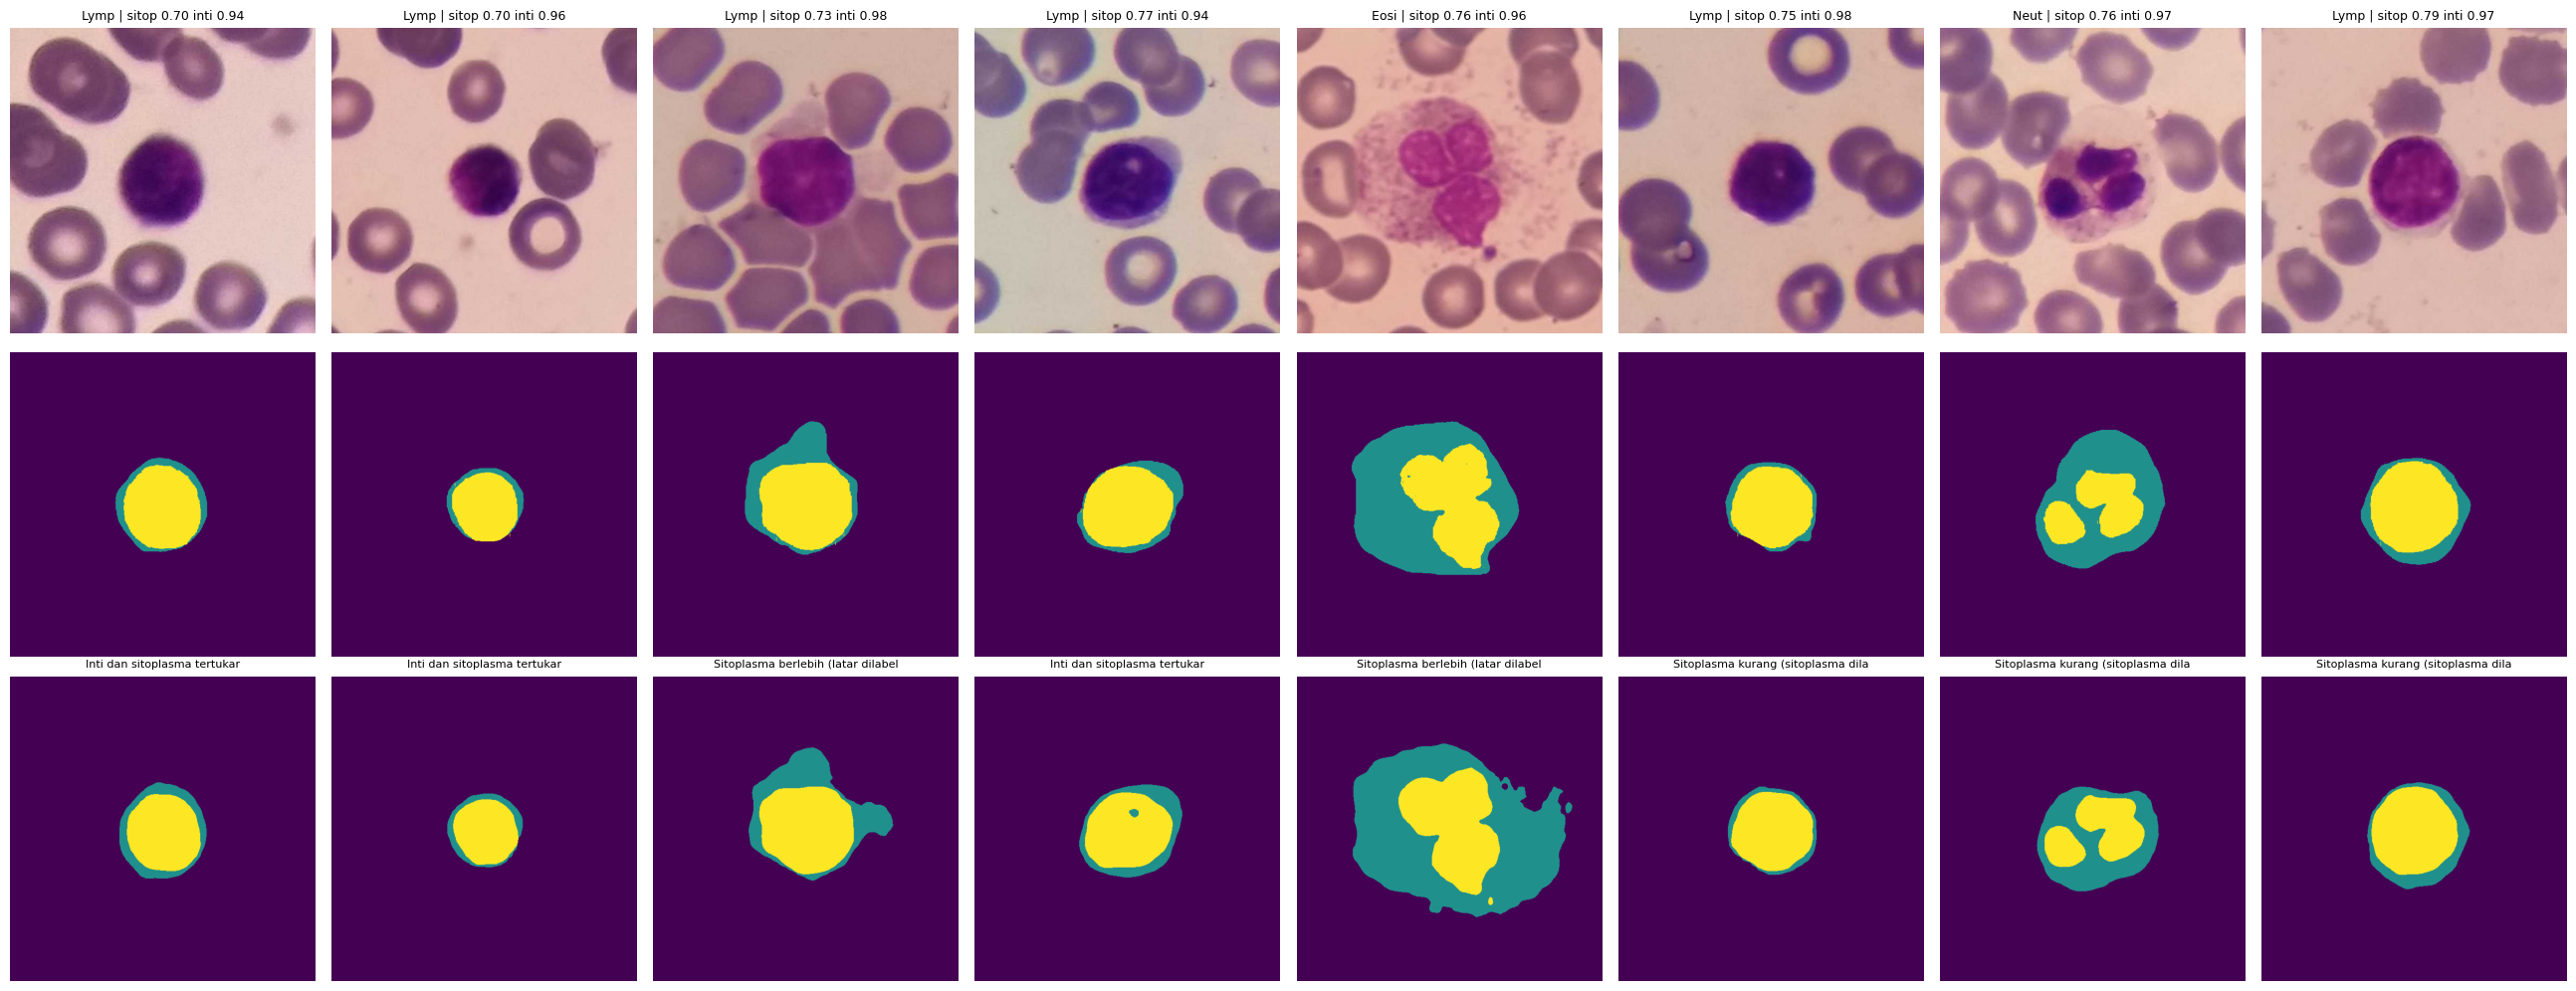

               name        cls  dice_cyto  dice_nuc                 kategori  objek_ekstra
 95-8-13-4_77_3.bmp Lymphocyte      0.698     0.940 inti_sitoplasma_tertukar         False
95-8-13-4_198_1.bmp Lymphocyte      0.705     0.958 inti_sitoplasma_tertukar         False
95-8-12-5_104_1.bmp Lymphocyte      0.730     0.979      sitoplasma_berlebih         False
95-8-13-4_354_1.bmp Lymphocyte      0.769     0.943 inti_sitoplasma_tertukar         False
 95-5-5-1_144_1.bmp Eosinophil      0.759     0.959      sitoplasma_berlebih         False
95-8-13-4_153_1.bmp Lymphocyte      0.745     0.981        sitoplasma_kurang         False
  95-8-8-3_75_2.bmp Neutrophil      0.756     0.974        sitoplasma_kurang         False
 95-8-8-3_147_2.bmp Lymphocyte      0.794     0.973        sitoplasma_kurang         False


In [28]:
# ===== SEL 4: galeri 8 segmentasi terburuk =====
worst = res.sort_values("dice_rerata").head(8)
fig, ax = plt.subplots(3, 8, figsize=(26, 10))
for j, r in enumerate(worst.itertuples()):
    img, gt, _ = get_sample(r.name, SIZE)
    ax[0, j].imshow(img); ax[0, j].set_title(f"{r.cls[:4]} | sitop {r.dice_cyto:.2f} inti {r.dice_nuc:.2f}", fontsize=9)
    ax[1, j].imshow(gt, vmin=0, vmax=2, cmap="viridis")
    ax[2, j].imshow(preds[r.name], vmin=0, vmax=2, cmap="viridis")
    ax[2, j].set_title(CAT_NAMES[r.kategori][:34] + ("\n+ objek ekstra" if r.objek_ekstra else ""), fontsize=8)
    for a in ax[:, j]: a.axis("off")
ax[0, 0].set_ylabel("citra"); ax[1, 0].set_ylabel("gt"); ax[2, 0].set_ylabel("prediksi")
plt.tight_layout(); plt.savefig(f"{DRIVE}/results/galeri_kesalahan_{ARCH}.png", dpi=80); plt.show()
print(worst[["name", "cls", "dice_cyto", "dice_nuc", "kategori", "objek_ekstra"]].round(3).to_string(index=False))


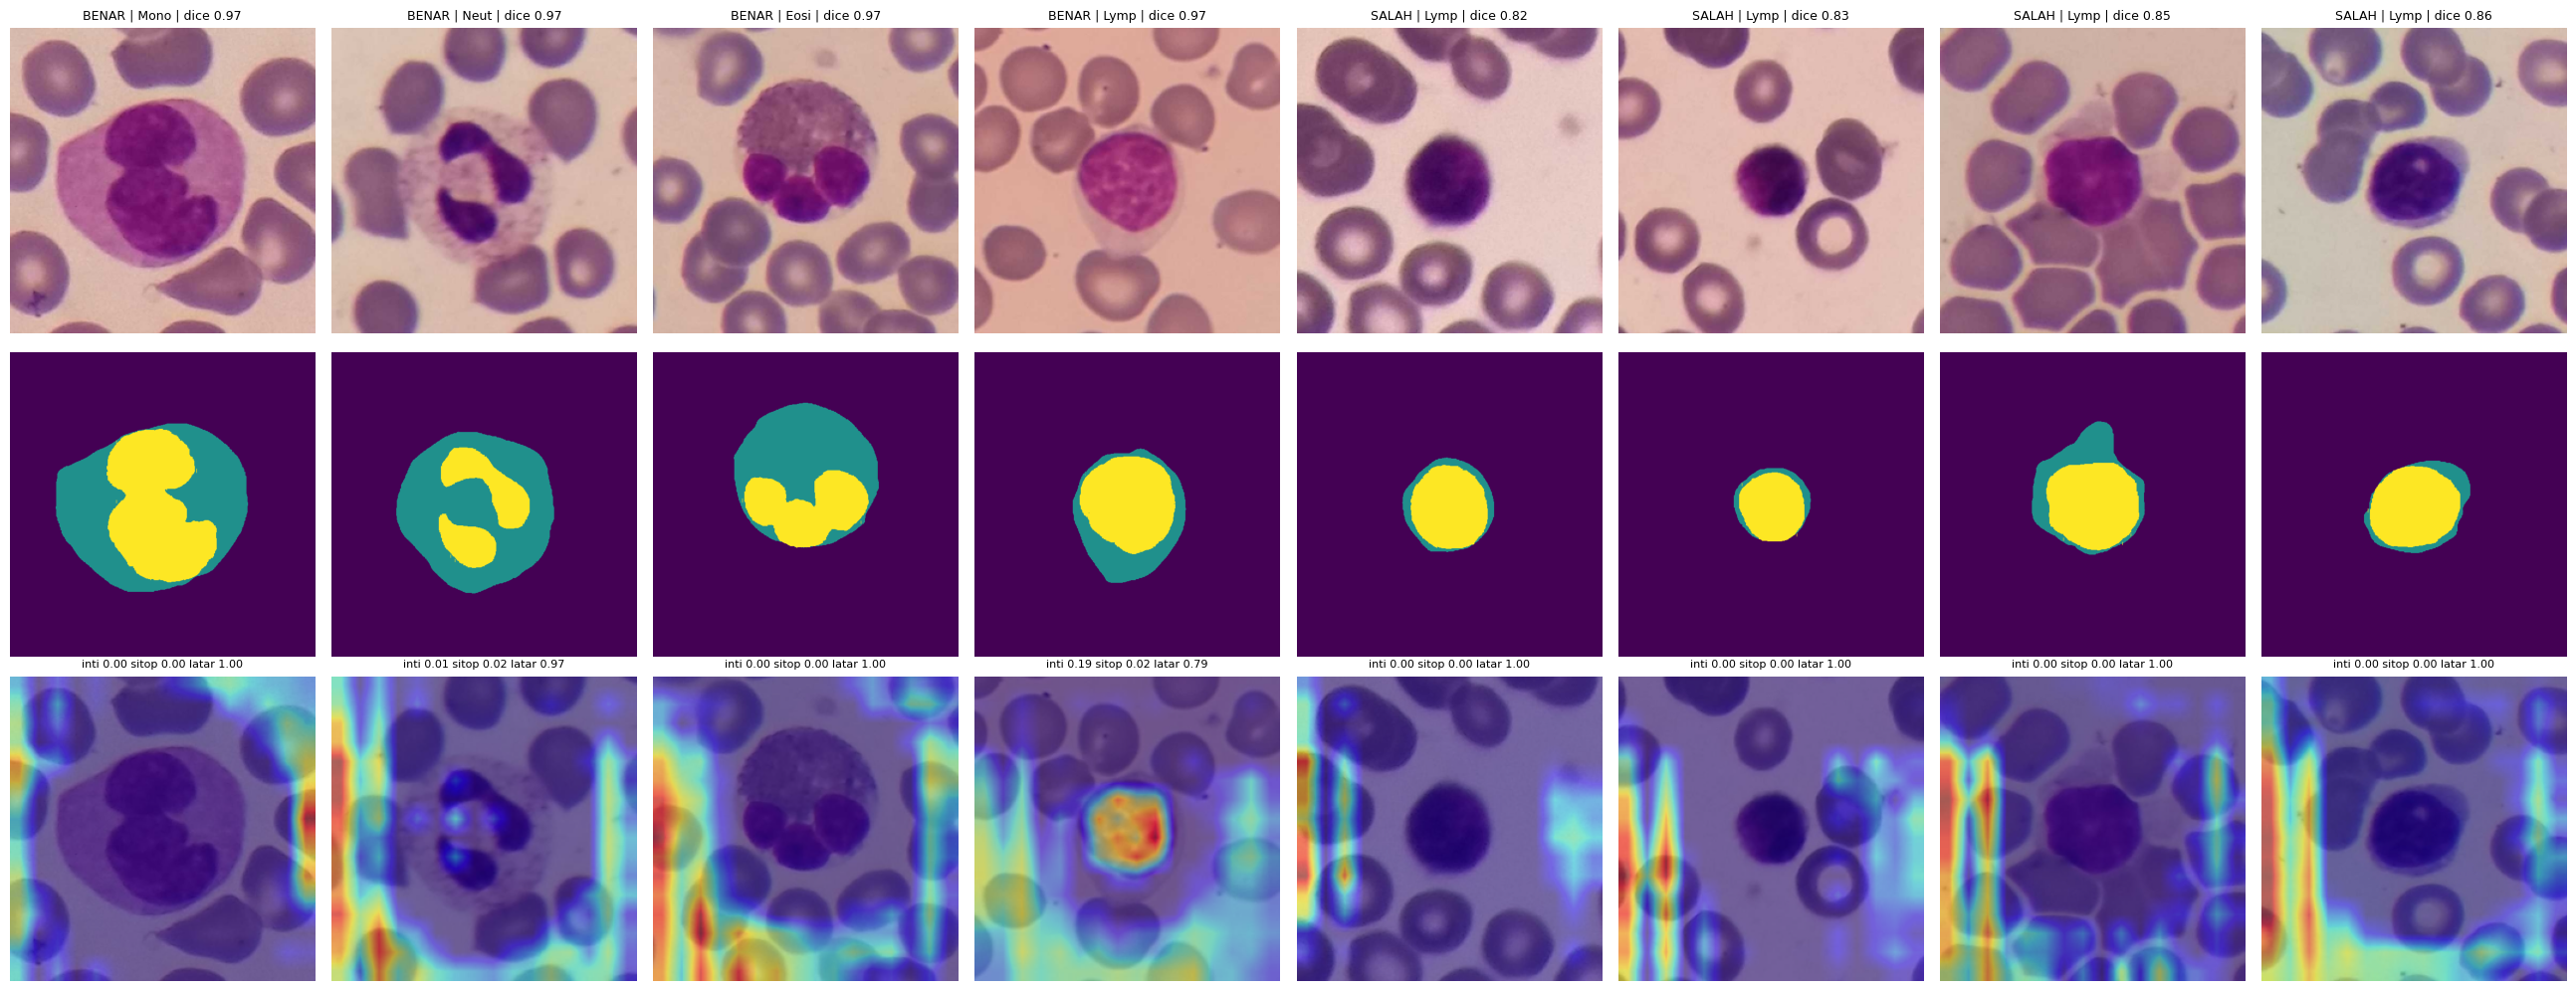

kasus                name        cls  inti  sitoplasma  latar
BENAR 95-8-13-4_106_1.bmp   Monocyte 0.000       0.000  1.000
BENAR 95-8-12-5_243_1.bmp Neutrophil 0.014       0.017  0.969
BENAR 95-8-17-1_184_1.bmp Eosinophil 0.000       0.000  1.000
BENAR  95-5-5-1_139_1.bmp Lymphocyte 0.194       0.016  0.790
SALAH  95-8-13-4_77_3.bmp Lymphocyte 0.000       0.000  1.000
SALAH 95-8-13-4_198_1.bmp Lymphocyte 0.000       0.000  1.000
SALAH 95-8-12-5_104_1.bmp Lymphocyte 0.000       0.000  1.000
SALAH 95-8-13-4_354_1.bmp Lymphocyte 0.000       0.000  1.000

Rerata porsi energi peta, kasus BENAR vs SALAH:
        inti  sitoplasma  latar
kasus                          
BENAR  0.052       0.008   0.94
SALAH  0.000       0.000   1.00


In [29]:
# ===== SEL 5: Grad-CAM, 4 kasus benar dan 4 kasus salah =====
CLS_TARGET = 2                     # 1 = sitoplasma, 2 = nukleus (jalankan dua kali, ganti nilainya)
srt = res.sort_values("dice_rerata")
cases = [("BENAR", r) for r in srt.tail(4).itertuples()] + [("SALAH", r) for r in srt.head(4).itertuples()]

fig, ax = plt.subplots(3, 8, figsize=(26, 10)); shares = []
for j, (tag, r) in enumerate(cases):
    img, gt, x = get_sample(r.name, SIZE)
    cam = seg_gradcam(model, x, CLS_TARGET, preds[r.name], device)
    e = cam_energy_shares(cam, gt, SIZE); shares.append(dict(kasus=tag, name=r.name, cls=r.cls, **e))
    small = np.array(Image.fromarray(img).resize((SIZE, SIZE)))
    ax[0, j].imshow(small); ax[0, j].set_title(f"{tag} | {r.cls[:4]} | dice {r.dice_rerata:.2f}", fontsize=9)
    ax[1, j].imshow(gt, vmin=0, vmax=2, cmap="viridis")
    ax[2, j].imshow(small); ax[2, j].imshow(cam, cmap="jet", alpha=0.5)
    ax[2, j].set_title(f"inti {e['inti']:.2f} sitop {e['sitoplasma']:.2f} latar {e['latar']:.2f}", fontsize=8)
    for a in ax[:, j]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{DRIVE}/results/gradcam_{ARCH}_kelas{CLS_TARGET}.png", dpi=80); plt.show()
sh = pd.DataFrame(shares).round(3); print(sh.to_string(index=False))
print("\nRerata porsi energi peta, kasus BENAR vs SALAH:")
print(sh.groupby("kasus")[["inti", "sitoplasma", "latar"]].mean().round(3).to_string())
sh.to_csv(f"{DRIVE}/results/gradcam_porsi_{ARCH}_kelas{CLS_TARGET}.csv", index=False)


## Cara menafsirkan (ditulis oleh Anggota 4 setelah melihat gambar)

Jangan menyalin kalimat template. Jawab dengan melihat gambar dan angka porsi energi:

1. **Galeri:** kategori mana paling sering, dan pada jenis sel apa? Apakah cocok dengan temuan EDA (sitoplasma limfosit tipis)? Apakah kategorinya masuk akal secara visual, atau perlu diganti namanya?
2. **Grad-CAM, kelas sitoplasma:** pada kasus BENAR, peta lebih banyak jatuh di inti, sitoplasma, atau latar? Apakah pada kasus SALAH porsi latar atau tepi sel lebih besar?
3. **Grad-CAM, kelas nukleus:** ulangi dengan `CLS_TARGET = 2`.
4. **Keterbatasan:** satu seed (42), satu arsitektur per jalankan, delapan kasus saja. Peta Grad-CAM menunjukkan area yang memengaruhi skor, bukan bukti sebab-akibat.
5. **Risiko klinis:** model ini prototipe riset. Kesalahan sistematis pada jenis sel tertentu (mis. limfosit) berbahaya jika dipakai menghitung rasio nukleus/sitoplasma.

Jalankan notebook ini sekali lagi dengan `ARCH = "deeplabv3plus"` bila waktu cukup.